# T05 · K-Nearest Neighbors (Distance · Classification · Regression · เลือก k · Scale ก่อน/หลัง)

**ใช้เมื่อโจทย์ถาม:** คำนวณระยะ (Euclidean / Manhattan / Minkowski) จากจุดใหม่ · หา k เพื่อนบ้านใกล้สุด + vote ·
KNN classification / regression · ผลของการ scale (ก่อน vs หลัง normalize) · เลือก k ที่ดีที่สุด (CV / Optimize) · ทำนายข้อมูลใหม่

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** — `NEW_POINT` = ข้อมูลใหม่ที่โจทย์ให้ทำนาย, `K`, `METRIC` |
| 2 | Run All · §2 = คำนวณมือ (แสดงระยะทุกแถว) · §5 = เลือก k · §7 = KNN regression (config แยกในเซลล์) |

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../data/riding_mowers.csv"
TARGET    = "Ownership"
POS_LABEL = "Owner"
ID_COL    = None
DROP_COLS = []
NEW_POINT = {"Income": 60, "Lot_Size": 20}   # ข้อมูลใหม่ (dict / list ของ dict / path .csv) · None = ข้าม
K         = 3              # k ที่โจทย์กำหนด
METRIC    = "euclidean"    # "euclidean" | "manhattan" | "minkowski" (ใช้ P_MINKOWSKI)
P_MINKOWSKI = 3
WEIGHTS   = "uniform"      # "uniform" = vote เท่ากัน | "distance" = ใกล้กว่าเสียงดังกว่า (1/d)
SCALE     = "standard"     # "standard" | "minmax" | None  (KNN ควร scale เสมอ)
K_MAX     = 25             # ลอง k = 1..K_MAX ตอนหา k ที่ดีที่สุด
EVAL_MODE = "cv"           # "cv" | "holdout"
N_FOLDS, TEST_SIZE, SEED = 5, 0.2, 42
MISSING_MARKERS, SHEET, CSV_SEP = ["?", "", " ", "NA"], 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        df = pd.read_csv(path, sep=sep)
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": float(mean_absolute_error(y_true, y_pred)), "MSE": float(mse), "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_true, y_pred))}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §1 โหลด + ภาพข้อมูล (2 feature แรก) + จุดใหม่

โหลด ../data/riding_mowers.csv → 24 แถว × 3 คอลัมน์
shape: (24, 3) | แถวซ้ำ: 0


,dtype,missing,missing_%,unique,example
Income,float64,0,0.0000,22,60.0000
Lot_Size,float64,0,0.0000,18,18.4000
Ownership,str,0,0.0000,2,Owner


การกระจายของ target 'Ownership':


,count,ratio
Ownership,,
Owner,12,0.5000
Nonowner,12,0.5000


X: (24, 2) | y = 'Ownership' → 1 = 'Owner' (positive), 0 = 'Nonowner' | ตัดคอลัมน์: []


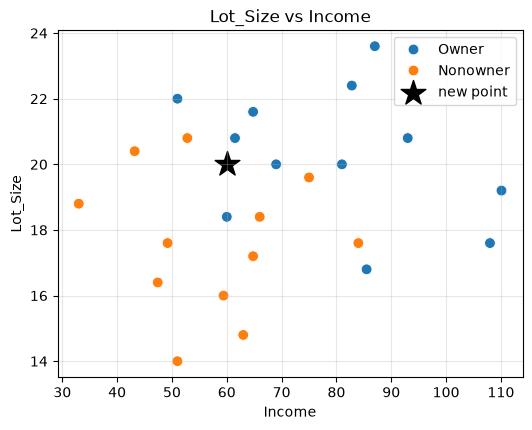

In [3]:
df = load_data(DATA_PATH)
check(df, TARGET)
X, y = make_xy(df)
new = align_new(new_data(NEW_POINT), X) if NEW_POINT is not None else None
nums = num_cols(X)
if len(nums) >= 2:
    fx, fy = nums[:2]                          # ✏️ เปลี่ยนคู่แกนที่จะวาดได้
    plt.figure(figsize=(6, 4.5))
    sns.scatterplot(x=X[fx], y=X[fy], hue=df.loc[X.index, TARGET], s=60)
    if new is not None:
        plt.scatter(new[fx], new[fy], marker="*", s=350, c="k", label="new point"); plt.legend()
    plt.title(f"{fy} vs {fx}"); plt.show()

## §2 คำนวณระยะทางด้วยมือ → k เพื่อนบ้านใกล้สุด → vote
- Euclidean $d=\sqrt{\sum (x_i-q_i)^2}$ · Manhattan $d=\sum |x_i-q_i|$ · Minkowski $d=(\sum |x_i-q_i|^p)^{1/p}$
- ตารางแรก = **ไม่ scale** · ตารางที่สอง = **หลัง scale** (ใช้ค่า mean/std หรือ min/max จากข้อมูล train) → ดูว่าเพื่อนบ้านเปลี่ยนไหม

In [4]:
def dist(A, q, metric=METRIC, p=P_MINKOWSKI):
    D = np.abs(A - q)
    if metric == "manhattan":
        return D.sum(axis=1)
    if metric == "minkowski":
        return (D ** p).sum(axis=1) ** (1 / p)
    return np.sqrt((D ** 2).sum(axis=1))

def neighbor_table(A, q, label, title):
    d = dist(A, q)
    t = pd.DataFrame(A, columns=feat_names, index=label.index).assign(**{TARGET: label.values, "distance": d})
    t = t.sort_values("distance"); t["rank"] = range(1, len(t) + 1)
    print(f"── {title} — {METRIC} ──"); display(t.head(max(K + 3, 6)).round(4))
    top = t.head(K)
    if WEIGHTS == "distance":
        w = 1 / top["distance"].replace(0, 1e-9); vote = w.groupby(top[TARGET]).sum().sort_values(ascending=False)
    else:
        vote = top[TARGET].value_counts()
    print(f"k = {K} เพื่อนบ้าน: {top[TARGET].tolist()} → vote { {k: round(float(v), 3) for k, v in vote.items()} } → ทำนาย = {vote.index[0]!r}")
    return t, vote.index[0]

if new is not None:
    prep_n = build_prep(X, scale=None).fit(X)                 # impute + one-hot (ไม่ scale)
    feat_names = list(prep_n.get_feature_names_out())
    A_raw, q_raw = prep_n.transform(X), prep_n.transform(new.iloc[[0]])[0]
    label = df.loc[X.index, TARGET]
    t_raw, pred_raw = neighbor_table(A_raw, q_raw, label, "ไม่ scale")

    prep_s = build_prep(X).fit(X)                             # impute + one-hot + scale ตาม SCALE
    A_s, q_s = prep_s.transform(X), prep_s.transform(new.iloc[[0]])[0]
    print("จุดใหม่หลัง scale:", {f: round(float(v), 4) for f, v in zip(feat_names, q_s)})
    t_s, pred_s = neighbor_table(A_s, q_s, label, f"scale = {SCALE}")
    print(f"✍️ จุดใหม่ {new.iloc[0].to_dict()} · k={K} · {METRIC}: ไม่ scale ทำนาย {pred_raw!r} / หลัง scale ทำนาย {pred_s!r}"
          + (" → เพื่อนบ้านเปลี่ยนเพราะตัวแปรหน่วยใหญ่ครอบงำระยะเมื่อไม่ scale" if pred_raw != pred_s else ""))

── ไม่ scale — euclidean ──


,Income,Lot_Size,Ownership,distance,rank
0,60.0000,18.4000,Owner,1.6000,1
3,61.5000,20.8000,Owner,1.7000,2
18,59.4000,16.0000,Nonowner,4.0447,3
2,64.8000,21.6000,Owner,5.0596,4
14,64.8000,17.2000,Nonowner,5.5570,5
23,63.0000,14.8000,Nonowner,6.0033,6


k = 3 เพื่อนบ้าน: ['Owner', 'Owner', 'Nonowner'] → vote {'Owner': 2.0, 'Nonowner': 1.0} → ทำนาย = 'Owner'
จุดใหม่หลัง scale: {'Income': -0.4355, 'Lot_Size': 0.4417}
── scale = standard — euclidean ──


,Income,Lot_Size,Ownership,distance,rank
3,-0.3580,0.7782,Owner,0.3453,1
8,0.0290,0.4417,Owner,0.4645,2
13,-0.8070,0.7782,Nonowner,0.5013,3
0,-0.4355,-0.2314,Owner,0.6731,4
2,-0.1877,1.1148,Owner,0.7172,5
19,-0.1258,-0.2314,Nonowner,0.7409,6


k = 3 เพื่อนบ้าน: ['Owner', 'Owner', 'Nonowner'] → vote {'Owner': 2.0, 'Nonowner': 1.0} → ทำนาย = 'Owner'
✍️ จุดใหม่ {'Income': 60, 'Lot_Size': 20} · k=3 · euclidean: ไม่ scale ทำนาย 'Owner' / หลัง scale ทำนาย 'Owner'


**✍️ คำตอบ §2:** ระยะจากจุดใหม่ถึงแถวที่ใกล้ที่สุด … คือ … · k = … เพื่อนบ้านเป็นคลาส … → ทำนาย … (vote …:…)

## §3 KNN แบบ hold-out (train/test) — scaler fit บน train เท่านั้น

,model,settings,accuracy,precision,recall,f1,train_accuracy
0,Majority baseline,,0.4000,0.4000,1.0000,0.5714,0.5263
1,KNN k=3,"euclidean, uniform, standard",1.0000,1.0000,1.0000,1.0000,0.7895


,pred 0,pred 1
actual 0,3,0
actual 1,0,2


TN=3  FP=0  FN=0  TP=2
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000         3
           1     1.0000    1.0000    1.0000         2

    accuracy                         1.0000         5
   macro avg     1.0000    1.0000    1.0000         5
weighted avg     1.0000    1.0000    1.0000         5



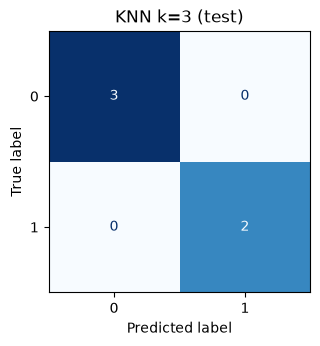

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
knn = make_pipe(KNeighborsClassifier(n_neighbors=K, metric=METRIC, p=P_MINKOWSKI, weights=WEIGHTS), X)
row = evaluate_holdout(f"KNN k={K}", knn, X_train, y_train, X_test, y_test, settings=f"{METRIC}, {WEIGHTS}, {SCALE}")
results_table([evaluate_holdout("Majority baseline", DummyClassifier(), X_train, y_train, X_test, y_test), row])
show_cm(y_test, knn.predict(X_test), title=f"KNN k={K} (test)")

## §4 CV: baseline vs KNN ไม่ scale vs scale (เปรียบเทียบก่อน/หลัง preprocessing)

In [6]:
cv = get_cv()
def knn_model(k=K):
    return KNeighborsClassifier(n_neighbors=k, metric=METRIC, p=P_MINKOWSKI, weights=WEIGHTS)
rows = [evaluate("Majority baseline", DummyClassifier(strategy="most_frequent"), X, y, cv),
        evaluate(f"KNN k={K} ไม่ scale", make_pipe(knn_model(), X, scale=None), X, y, cv, "raw"),
        evaluate(f"KNN k={K} z-score", make_pipe(knn_model(), X, scale="standard"), X, y, cv, "standard"),
        evaluate(f"KNN k={K} min-max", make_pipe(knn_model(), X, scale="minmax"), X, y, cv, "minmax")]
t4 = results_table(rows)
say_compare(t4, "f1", "Majority baseline")

,model,settings,accuracy,precision,recall,f1,f1_std
0,Majority baseline,,0.4200,0.1600,0.4000,0.2286,0.2799
1,KNN k=3 ไม่ scale,raw,0.7000,0.7500,0.7667,0.7048,0.1978
2,KNN k=3 z-score,standard,0.7400,0.7000,0.8000,0.7400,0.2498
3,KNN k=3 min-max,minmax,0.7800,0.7667,0.8000,0.7800,0.2713


✍️ โมเดลที่ดีที่สุดตาม f1 คือ KNN k=3 min-max (minmax) ได้ f1 = 0.7800 เทียบกับ baseline (Majority baseline) ที่ได้ 0.2286 ต่างกัน +0.5514 (baseline accuracy = 0.4200 แต่ f1 ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)


**✍️ คำตอบ §4:** KNN ไม่ scale ได้ … หลัง scale ได้ … → ดีขึ้นเพราะ KNN ใช้ระยะทาง ตัวแปรหน่วยใหญ่ไม่ครอบงำ · เหนือ baseline …

## §5 เลือก k ที่ดีที่สุด (k-curve + GridSearchCV)
k เล็ก = เส้นแบ่งซับซ้อน → overfit (train สูง CV ต่ำ) · k ใหญ่ = เรียบเกิน → underfit · binary ควรใช้ k คี่ (กันเสมอ)

,k,train_acc,cv_acc,cv_f1,cv_recall
0,1,1.000000,0.580000,0.560000,0.566700
1,2,0.811600,0.580000,0.400000,0.333300
2,3,0.863700,0.740000,0.740000,0.800000
3,4,0.863700,0.700000,0.680000,0.666700
4,5,0.811600,0.740000,0.740000,0.800000
5,6,0.853700,0.700000,0.700000,0.733300
6,7,0.791600,0.740000,0.740000,0.800000
7,8,0.800500,0.740000,0.693300,0.666700
8,9,0.822600,0.780000,0.760000,0.800000
9,10,0.843200,0.700000,0.660000,0.666700


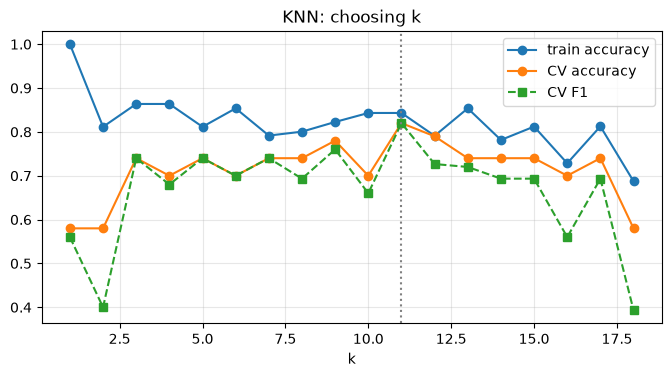

✍️ k ที่ดีที่สุด (CV F1) = 11 → F1 0.8200, accuracy 0.8200 · k=1 train acc 1.000 vs CV 0.580 = overfit


GridSearch best: {'model__metric': 'euclidean', 'model__n_neighbors': 11, 'model__weights': 'uniform'} | CV F1 = 0.82


,param_model__metric,param_model__n_neighbors,param_model__weights,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,euclidean,11,uniform,0.8200,0.7667,0.9000,0.8200
1,euclidean,9,uniform,0.7800,0.7333,0.8000,0.7600
2,manhattan,11,uniform,0.7800,0.7333,0.8000,0.7600
3,euclidean,3,uniform,0.7400,0.7000,0.8000,0.7400
4,euclidean,5,uniform,0.7400,0.7000,0.8000,0.7400
5,euclidean,7,uniform,0.7400,0.7000,0.8000,0.7400
6,manhattan,7,uniform,0.7400,0.7000,0.8000,0.7400
7,manhattan,5,uniform,0.7400,0.7000,0.8000,0.7400


In [7]:
ks = list(range(1, min(K_MAX, int(len(X) * (1 - 1 / N_FOLDS)) - 1) + 1))
curve = []
for k in ks:
    r = cross_validate(make_pipe(knn_model(k), X), X, y, cv=cv, scoring=cls_scoring(y), return_train_score=True)
    curve.append({"k": k, "train_acc": r["train_accuracy"].mean(), "cv_acc": r["test_accuracy"].mean(),
                  "cv_f1": r["test_f1"].mean(), "cv_recall": r["test_recall"].mean()})
curve = pd.DataFrame(curve)
best = curve.loc[curve["cv_f1"].idxmax()]
display(curve.round(4).style.highlight_max(subset=["cv_acc", "cv_f1"], color="#c8e6c9"))
plt.figure(figsize=(8, 3.8))
plt.plot(curve.k, curve.train_acc, "o-", label="train accuracy"); plt.plot(curve.k, curve.cv_acc, "o-", label="CV accuracy")
plt.plot(curve.k, curve.cv_f1, "s--", label="CV F1"); plt.axvline(best.k, color="gray", ls=":")
plt.xlabel("k"); plt.title("KNN: choosing k"); plt.legend(); plt.show()
print(f"✍️ k ที่ดีที่สุด (CV F1) = {int(best.k)} → F1 {best.cv_f1:.4f}, accuracy {best.cv_acc:.4f} · k=1 train acc {curve.train_acc.iloc[0]:.3f} vs CV {curve.cv_acc.iloc[0]:.3f} = overfit")

grid = GridSearchCV(make_pipe(KNeighborsClassifier(), X),
                    {"model__n_neighbors": ks, "model__weights": ["uniform", "distance"],
                     "model__metric": ["euclidean", "manhattan"]},
                    cv=cv, scoring=cls_scoring(y), refit="f1").fit(X, y)
print("GridSearch best:", grid.best_params_, "| CV F1 =", round(grid.best_score_, 4))
display(top_k(grid, 8))

**✍️ คำตอบ §5:** เลือก k = … (CV F1 …) · k น้อยเกินไป overfit (train … CV …) · k มากเกินไป underfit · ก่อน optimize (k=…) F1 … → หลัง … (+…)

## §6 โมเดลสุดท้าย → ทำนายข้อมูลใหม่ (probability = สัดส่วน vote)

In [8]:
final = grid.best_estimator_            # ✏️ หรือใช้ make_pipe(knn_model(K), X).fit(X, y) ถ้าโจทย์บังคับ k
final.fit(X, y)
results_table([evaluate("Majority baseline", DummyClassifier(), X, y, cv),
               evaluate(f"KNN k={K} (default)", make_pipe(knn_model(), X), X, y, cv),
               evaluate("KNN optimized", grid.best_estimator_, X, y, cv, str(grid.best_params_))])
if new is not None:
    proba = final.predict_proba(new)
    out = new.copy(); out["pred"] = final.predict(new)
    for i, c in enumerate(final.classes_):
        out[f"P(class={c})"] = proba[:, i]
    display(out)
    Aq = final.named_steps["prep"].transform(new.iloc[[0]])
    nn = NearestNeighbors(n_neighbors=final.named_steps["model"].n_neighbors,
                          metric=final.named_steps["model"].metric).fit(final.named_steps["prep"].transform(X))
    d_, idx = nn.kneighbors(Aq)
    print("เพื่อนบ้านของจุดใหม่ (แถวในข้อมูล):"); display(df.loc[X.index[idx[0]]].assign(distance=d_[0]))

,model,settings,accuracy,precision,recall,f1,f1_std
0,Majority baseline,,0.4200,0.1600,0.4000,0.2286,0.2799
1,KNN k=3 (default),,0.7400,0.7000,0.8000,0.7400,0.2498
2,KNN optimized,"{'model__metric': 'euclidean', 'model__n_neigh...",0.8200,0.7667,0.9000,0.8200,0.1833


,Income,Lot_Size,pred,P(class=0),P(class=1)
0,60,20,1,0.4545,0.5455


เพื่อนบ้านของจุดใหม่ (แถวในข้อมูล):


,Income,Lot_Size,Ownership,distance
3,61.5000,20.8000,Owner,0.3453
8,69.0000,20.0000,Owner,0.4645
13,52.8000,20.8000,Nonowner,0.5013
0,60.0000,18.4000,Owner,0.6731
2,64.8000,21.6000,Owner,0.7172
19,66.0000,18.4000,Nonowner,0.7409
12,75.0000,19.6000,Nonowner,0.7922
15,43.2000,20.4000,Nonowner,0.8832
10,51.0000,22.0000,Owner,0.9610
11,81.0000,20.0000,Owner,1.0838


**✍️ คำตอบ §6:** จุดใหม่ถูกทำนายเป็น … ความน่าจะเป็น … (เพื่อนบ้าน … จาก … เป็นคลาสนี้)

## §7 KNN Regression (ทำนายตัวเลข = ค่าเฉลี่ยของ y ของ k เพื่อนบ้าน)
มี config แยกในเซลล์ — ใช้เมื่อโจทย์ให้ทำนายตัวเลขด้วย KNN · metric = MAE / RMSE / R² · เทียบกับ mean baseline

โหลด ../mock_lab/mock2_regression_pca/data/housing.csv → 503 แถว × 14 คอลัมน์
X: (503, 13) | y = 'medv' (ตัวเลข) | ตัดคอลัมน์: []


,model,settings,MAE,MSE,RMSE,R2
0,Mean baseline,,6.6787,84.9293,9.2157,-0.0017
1,KNN reg k=5 ไม่ scale,,4.3721,39.8727,6.3145,0.5307
2,KNN reg k=5 z-score,,2.8562,20.1232,4.4859,0.7579
3,Linear Regression,,3.3779,23.3049,4.8275,0.7239
4,KNN reg optimized,"{'model__n_neighbors': 4, 'model__weights': 'd...",2.6594,18.3852,4.2878,0.7795


✍️ โมเดลที่ดีที่สุดตาม RMSE คือ KNN reg optimized ({'model__n_neighbors': 4, 'model__weights': 'distance'}) ได้ RMSE = 4.2878 เทียบกับ baseline (Mean baseline) ที่ได้ 9.2157 ต่างกัน -4.9279


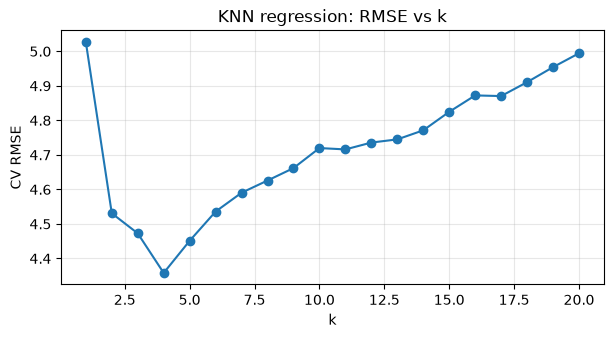

In [9]:
REG_DATA_PATH = "../mock_lab/mock2_regression_pca/data/housing.csv"   # ✏️
REG_TARGET    = "medv"                                                # ✏️ target ตัวเลข
REG_DROP      = []                                                    # ✏️
REG_NEW       = None          # ✏️ dict ข้อมูลใหม่ · None = ข้าม
REG_K         = 5             # ✏️

rdf = load_data(REG_DATA_PATH)
Xr, yr = make_xy(rdf, target=REG_TARGET, drop=REG_DROP, task="regression")
cvr = get_cv("regression")
rrows = [evaluate_reg("Mean baseline", DummyRegressor(strategy="mean"), Xr, yr, cvr),
         evaluate_reg(f"KNN reg k={REG_K} ไม่ scale", make_pipe(KNeighborsRegressor(REG_K), Xr, scale=None), Xr, yr, cvr),
         evaluate_reg(f"KNN reg k={REG_K} z-score", make_pipe(KNeighborsRegressor(REG_K), Xr, scale="standard"), Xr, yr, cvr),
         evaluate_reg("Linear Regression", make_pipe(LinearRegression(), Xr), Xr, yr, cvr)]
rgrid = GridSearchCV(make_pipe(KNeighborsRegressor(), Xr), {"model__n_neighbors": range(1, 21), "model__weights": ["uniform", "distance"]},
                     cv=cvr, scoring="neg_root_mean_squared_error").fit(Xr, yr)
rrows.append(evaluate_reg("KNN reg optimized", rgrid.best_estimator_, Xr, yr, cvr, str(rgrid.best_params_)))
rt = results_table(rrows)
say_compare(rt, "RMSE", "Mean baseline", higher_is_better=False)
kc = pd.DataFrame(rgrid.cv_results_); kc = kc[kc.param_model__weights == "uniform"]
plt.figure(figsize=(7, 3.3)); plt.plot(kc.param_model__n_neighbors, -kc.mean_test_score, "o-"); plt.xlabel("k"); plt.ylabel("CV RMSE"); plt.title("KNN regression: RMSE vs k"); plt.show()
if REG_NEW is not None:
    print("ทำนาย:", rgrid.best_estimator_.predict(align_new(new_data(REG_NEW), Xr)))

**✍️ คำตอบ §7:** KNN regression (k = …) ได้ RMSE … R² … ดีกว่า mean baseline (RMSE …) · scale แล้ว RMSE ลดจาก … เป็น …